# Experiment 4, Q11: Student Performance Prediction Using Linear Regression

**Aim:** Predict a student's **Performance Index** using the available academic and behavioral features.

**Dataset:** `Student_Performance.csv` (place in the notebook working directory). This dataset does **not** contain an attendance column or a separate final-exam-score column, so the target used is `Performance Index`.

## 1. Import the required libraries
- `pandas`: read and work with the CSV.
- `matplotlib`: plot relationships.
- `train_test_split`: reserve test records.
- `LinearRegression`: train the prediction model.
- Metric functions: evaluate predictions.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## 2. Load and inspect
`head()` shows five examples; `isnull().sum()` counts missing values; `describe()` summarizes numeric data.

In [2]:
df = pd.read_csv("Student_Performance.csv")
print(df.head())
print("Missing values:\n", df.isnull().sum())
print(df.describe())

   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  
Missing values:
 Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Pra

## 3. Examine relationships (EDA)
Use scatter plots to compare study hours and previous scores with the Performance Index. Each dot is a student.

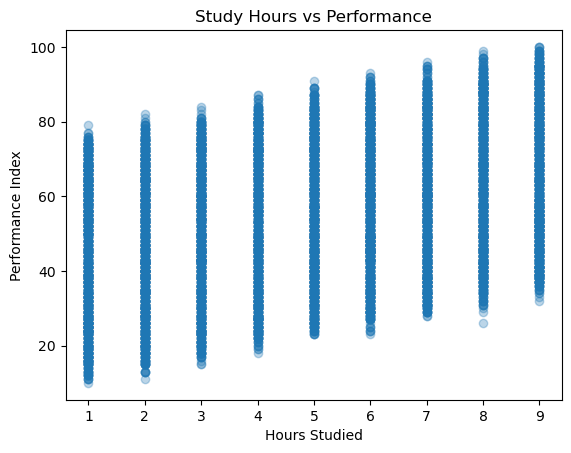

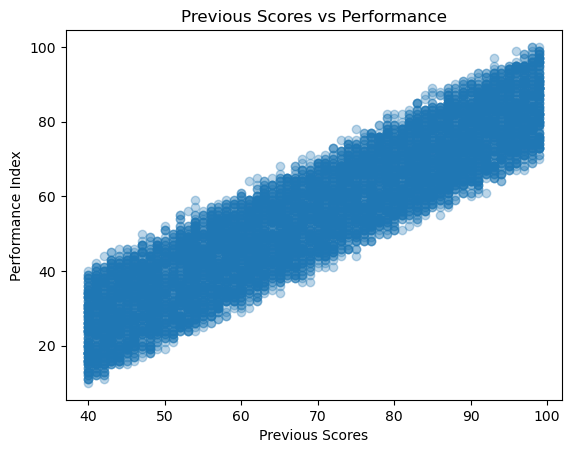

In [3]:
plt.scatter(df["Hours Studied"], df["Performance Index"], alpha=0.3)
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.title("Study Hours vs Performance")
plt.show()

plt.scatter(df["Previous Scores"], df["Performance Index"], alpha=0.3)
plt.xlabel("Previous Scores")
plt.ylabel("Performance Index")
plt.title("Previous Scores vs Performance")
plt.show()

## 4. Convert text to numbers; select input features and target
`map()` replaces Yes/No with 1/0. `X` contains all five features; `y` is the Performance Index.

In [4]:
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["Performance Index"])
y = df["Performance Index"]

## 5. Train-test split
80% training, 20% testing. `random_state=42` ensures repeatable splits.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 6. Train the model and predict test records
`fit` learns from the training records. `predict` estimates performance on unseen test records.

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## 7. Evaluate and interpret feature directions
Higher R² is better. Lower MAE and RMSE are better. Positive coefficients mean higher predicted performance for an increase in that feature, keeping others fixed.

In [7]:
print("R2 Score:", round(r2_score(y_test, y_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(mean_squared_error(y_test, y_pred) ** 0.5, 2))
print("\nFeature coefficients:")
print(pd.Series(model.coef_, index=X.columns).round(3))

R2 Score: 0.989
MAE: 1.61
RMSE: 2.02

Feature coefficients:
Hours Studied                       2.852
Previous Scores                     1.017
Extracurricular Activities          0.609
Sleep Hours                         0.477
Sample Question Papers Practiced    0.192
dtype: float64


## 8. Predict one new student
Use exactly the same input columns as the training data. `1` for Extracurricular Activities means Yes. The estimated value is a **Performance Index**, not a guaranteed examination mark.

In [8]:
new_student = pd.DataFrame([{
    "Hours Studied": 6,
    "Previous Scores": 75,
    "Extracurricular Activities": 1,
    "Sleep Hours": 7,
    "Sample Question Papers Practiced": 5
}])
print("Predicted Performance Index:", round(model.predict(new_student)[0], 2))

Predicted Performance Index: 64.37
